## 📘 Guia de Uso - Experimentos Automatizados

### 🎯 Objetivo
Este conjunto de células automatiza o teste de **todas as combinações possíveis de features** (de 3 a 6 features por experimento) e salva cada resultado no **MLflow** para análise posterior.

---

### 🛠️ Como Usar

1. **Execute as células** 

2. **Ajuste o número de combinações** (opcional):
   - Por padrão: testa combinações de **3 a 6 features** = **~33.649 experimentos**
   - Para teste rápido: descomente a linha de `random.sample()` na primeira célula para limitar a 100 combinações
   - Para mais features: mude `range(3, 7)` para `range(1, 7)` (vai aumentar MUITO o tempo)

3. **Execute a célula de geração de combinações** (primeira célula criada)

4. **Execute a célula do loop principal** (segunda célula):
   - Vai rodar por **várias horas** dependendo do número de combinações
   - Progress updates a cada 50 experimentos
   - Todos os resultados são salvos no MLflow automaticamente

5. **Execute a célula de análise** para ver:
   - Top 20 melhores combinações
   - Estatísticas por número de features
   - Gráficos comparativos
   - Features mais importantes

6. **(Opcional)** Execute a célula de Random Forest para testar RF na melhor combinação encontrada

---

### 📊 O Que é Salvo no MLflow

Para **cada experimento**:
- **Parâmetros**: features usadas, número de features, tipo de modelo
- **Métricas**: Recall, Precision, F1-Score, **F2-Score**, AUC
- **Modelo**: Pipeline completo (preprocessor + classifier) salvo para deploy

---

### ⏱️ Tempo Estimado

| Combinações | Tempo Aproximado |
|---|---|
| 100 | ~5-10 minutos |
| 1.000 | ~1 hora |
| 10.000 | ~10 horas |
| 33.649 (completo) | ~30-35 horas |

⚠️ **Dica**: Comece com 100 combinações para testar, depois rode o conjunto completo overnight.

---

### 🔍 Como Acessar os Resultados no MLflow

1. Clique em **"Experiments"** no menu lateral esquerdo do Databricks
2. Procure por **`feature_combinations_experiment`**
3. Você pode:
   - Ordenar por qualquer métrica (F2-Score, AUC, Recall...)
   - Comparar múltiplos experimentos lado a lado
   - Fazer download dos modelos salvos
   - Criar gráficos personalizados

---

### 💡 Dicas de Otimização

**Para acelerar os experimentos:**
- Reduza o range de combinações para 4-6 features: `range(4, 7)`
- Use amostragem aleatória: `random.sample(all_combinations, 1000)`
- Teste primeiro só Logistic Regression (mais rápido que Random Forest)

**Para melhorar a qualidade:**
- Adicione mais modelos no loop (XGBoost, LightGBM...)
- Teste diferentes hiperparâmetros para cada combinação
- Use o conjunto de **validação** (`df_val`, `y_val`) para early stopping

---

### ✅ Próximos Passos

Após encontrar a melhor combinação:
1. Teste com **Random Forest** (célula opcional)
2. Faça **Grid Search** detalhado só nas top 10 combinações
3. Use a melhor combinação para **deploy em produção**
4. Salve o modelo final como **Registered Model** no MLflow
5. Testar um ensaio combinado

# Train Test Split


In [0]:
from sklearn.model_selection import train_test_split

# Load Spark DataFrame and convert to pandas for scikit-learn
df_spark = spark.table('adult_income.adult_income_gold.ad_inc_gold')
df_frame = df_spark.toPandas()

# Realizar split estratificado 60/20/20
y = df_frame['class'].apply(lambda x: 1 if x == '>50K' else 0)

# Primeiro split: 60% treino, 40% restante
df_train, df_temp, y_train_temp, y_temp = train_test_split(
    df_frame, y, test_size=0.4, random_state=42, stratify=y
)

# Segundo split: dividir os 40% em 20% validação e 20% teste
df_val, df_test, y_val_temp, y_test_temp = train_test_split(
    df_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Separar features (X) e target (y) para os conjuntos de treino e teste
X_train = df_train.drop(columns=['class'])
y_train = df_train['class'].apply(lambda x: 1 if x == '>50K' else 0)

X_val = df_val.drop(columns=['class'])
y_val = df_val['class'].apply(lambda x: 1 if x == '>50K' else 0)

X_test = df_test.drop(columns=['class'])
y_test = df_test['class'].apply(lambda x: 1 if x == '>50K' else 0)

print("✅ Conjuntos preparados:")
print(f"  X_train: {X_train.shape}")
print(f"  y_train: {y_train.shape} | Classe positiva (>50K): {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f"  X_val: {X_val.shape}")
print(f"  y_val: {y_val.shape} | Classe positiva (>50K): {y_val.sum()} ({y_val.mean()*100:.1f}%)")
print(f"  X_test: {X_test.shape}")
print(f"  y_test: {y_test.shape} | Classe positiva (>50K): {y_test.sum()} ({y_test.mean()*100:.1f}%)")

✅ Conjuntos preparados:
  X_train: (29305, 32)
  y_train: (29305,) | Classe positiva (>50K): 7012 (23.9%)
  X_val: (9768, 32)
  y_val: (9768,) | Classe positiva (>50K): 2337 (23.9%)
  X_test: (9769, 32)
  y_test: (9769,) | Classe positiva (>50K): 2338 (23.9%)


In [0]:
# ✅ VERIFICAÇÃO: Confirmar que os experimentos usam o split correto

print("="*80)
print("📊 VERIFICAÇÃO DO DATA SPLIT")
print("="*80)

print("\n🔢 Tamanhos dos conjuntos:")
print(f"  df_train (Treino):    {df_train.shape[0]:,} registros ({df_train.shape[0]/len(df_frame)*100:.1f}%)")
print(f"  df_val (Validação):   {df_val.shape[0]:,} registros ({df_val.shape[0]/len(df_frame)*100:.1f}%)")
print(f"  df_test (Teste):      {df_test.shape[0]:,} registros ({df_test.shape[0]/len(df_frame)*100:.1f}%)")
print(f"  Total:                {len(df_frame):,} registros")

print("\n✅ CONFIRMAÇÃO:")
print("  - Os experimentos automatizados (Cell 20) TREINAM com 'df_train' (60%)")
print("  - Os experimentos automatizados (Cell 20) AVALIAM com 'df_test' (20%)")
print("  - O conjunto 'df_val' (20%) está disponível para tuning futuro")

print("\n" + "="*80)
print("📝 Código relevante na Cell 20:")
print("="*80)
print("""\n  # Treinar
  X_train_combo = df_train[selected_features]  ← 60% do dataset
  pipeline.fit(X_train_combo, y_train)

  # Prever no conjunto de teste
  X_test_combo = df_test[selected_features]    ← 20% do dataset
  y_pred = pipeline.predict(X_test_combo)
""")

print("="*80)

📊 VERIFICAÇÃO DO DATA SPLIT

🔢 Tamanhos dos conjuntos:
  df_train (Treino):    29,305 registros (60.0%)
  df_val (Validação):   9,768 registros (20.0%)
  df_test (Teste):      9,769 registros (20.0%)
  Total:                48,842 registros

✅ CONFIRMAÇÃO:
  - Os experimentos automatizados (Cell 20) TREINAM com 'df_train' (60%)
  - Os experimentos automatizados (Cell 20) AVALIAM com 'df_test' (20%)
  - O conjunto 'df_val' (20%) está disponível para tuning futuro

📝 Código relevante na Cell 20:

  # Treinar
  X_train_combo = df_train[selected_features]  ← 60% do dataset
  pipeline.fit(X_train_combo, y_train)

  # Prever no conjunto de teste
  X_test_combo = df_test[selected_features]    ← 20% do dataset
  y_pred = pipeline.predict(X_test_combo)



# Pipeline

In [ ]:
%pip install catboost

from catboost import CatBoostClassifier
import pandas as pd

# vamos definir as colunas
selected_columns = [
    'age',
    'capital-loss',
    'class',
    'edu_x_hours',
    'hours-per-week',
    'is_capital_gain',
    'is_capital_loss',
    'is_from_United-States',
    'is_husb_and_not_in_fam',
    'is_husband',
    'is_male',
    'is_married',
    'is_married_and_not',
    'is_married_notmarried_divorced',
    'is_native-country_missing',
    'is_not_private',
    'is_not_white',
    'is_occupation_missing',
    'is_private',
    'is_white',
    'is_wife',
    'marital-status',
    'native-country',
    'occupation',
    'race',
    'relationship',
    'sex_ord',
    'workclass',
    'fnlwgt',
]

# variáveis categóricas nominais -> CatBoost trata nativamente via cat_features (sem OneHotEncoder)
categorical_features = [
    'marital-status',
    'native-country',
    'occupation',
    'race',
    'relationship',
    'workclass',
]

# variáveis numéricas contínuas -> CatBoost lida nativamente com NaN e não exige scaling
numeric_features = [
    'age',
    'capital-loss',
    'edu_x_hours',
    'education-num',
    'fnlwgt',
    'hours-per-week',
    'sex_ord',
]

# variáveis binárias (já 0/1)
binary_features = [
    'is_capital_gain',
    'is_capital_loss',
    'is_from_United-States',
    'is_husb_and_not_in_fam',
    'is_husband',
    'is_male',
    'is_married',
    'is_married_and_not',
    'is_married_notmarried_divorced',
    'is_native-country_missing',
    'is_not_private',
    'is_not_white',
    'is_occupation_missing',
    'is_private',
    'is_white',
    'is_wife',
]

def prepare_catboost_input(df, features, categorical_cols=categorical_features):
    """
    Substitui o ColumnTransformer/OneHotEncoder/StandardScaler: o CatBoost consome as
    colunas originais e trata as categóricas nativamente via cat_features.
    Categóricas precisam ser str (não float/NaN) -> cast + fillna('missing').
    Reutilizada em todas as células de treino/avaliação do CatBoost neste notebook.
    Retorna (X, lista_de_colunas_categoricas_presentes_em_features).
    """
    X = df[features].copy()
    cat_in_features = [c for c in categorical_cols if c in features]
    for col in cat_in_features:
        X[col] = X[col].astype(str).fillna('missing')
    return X, cat_in_features


### Aplicar o pipeline

---

# 🧪 Experimentos Automatizados - Combinações de Features

## Objetivo
Testar **automaticamente todas as combinações possíveis de features** (3-6 features por experimento) e salvar todos os resultados no **MLflow** para identificar a melhor combinação que maximiza o **F2-Score** (equilibrando Recall e Precision, com foco em Recall).

## O Que Será Feito
1. ✅ Gerar todas as combinações de 3-6 features
2. ✅ Para cada combinação: treinar Logistic Regression
3. ✅ Avaliar no conjunto de **teste** (df_test)
4. ✅ Salvar métricas e modelo no MLflow
5. ✅ Analisar resultados e identificar as melhores combinações
6. ✅ (Opcional) Testar Random Forest na melhor combinação

---

In [ ]:
import itertools
import mlflow
import mlflow.sklearn
import mlflow.catboost
from sklearn.metrics import recall_score, precision_score, f1_score, fbeta_score, roc_auc_score
import pandas as pd

# 1. Definir TODAS as features disponíveis (excluindo 'class')
all_numeric_features = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-loss',
    'hours-per-week',
    'sex_ord',
    'edu_x_hours'
]

all_categorical_features = [
    'marital-status',
    'native-country',
    'occupation',
    'race',
    'relationship',
    'workclass',
]

all_binary_features = [
    'is_capital_gain',
    'is_capital_loss',
    'is_from_United-States', 
    'is_husb_and_not_in_fam',
    'is_husband', 'is_male',
    'is_married', 'is_married_and_not',
    'is_married_notmarried_divorced',
    'is_native-country_missing',
    'is_not_private', 'is_not_white',
    'is_occupation_missing',
    'is_private',
    'is_white',
     'is_wife'
]

all_features = all_numeric_features + all_categorical_features + all_binary_features

print(f"Total de features disponíveis: {len(all_features)}")
print(f"Numéricas: {len(all_numeric_features)}")
print(f"Categóricas: {len(all_categorical_features)}")
print(f"Binárias: {len(all_binary_features)}")

# 2. Gerar todas as combinações (de 3 a 6 features para otimizar tempo)
all_combinations = []
for size in range(3, 7):  # 3 a 6 features
    all_combinations.extend(itertools.combinations(all_features, size))

print(f"\nTotal de combinações a testar: {len(all_combinations):,}")
print("Distribuição por tamanho:")
for size in range(3, 7):
    count = len(list(itertools.combinations(all_features, size)))
    print(f"  {size} features: {count:,} combinações")

print(f"\n⚠️ Nota: {len(all_combinations):,} experimentos serão executados. Isso pode levar várias horas.")
print("Para testar rápido, descomente a linha de amostragem aleatória acima.")


In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score
import random
import pandas as pd


core_features = ['age', 'education-num', 'hours-per-week']  # ajusta às tuas features fixas
candidate_features = [f for f in all_features if f not in core_features]

random.seed(42)  # reprodutibilidade caso haja sampling em outras partes do notebook

# CatBoost: sem ColumnTransformer/OHE/scaling — cat_features nativo via prepare_catboost_input
X_train_cand, categorical_in_cand = prepare_catboost_input(df_train, candidate_features)
X_val_cand, _ = prepare_catboost_input(df_val, candidate_features)

param_dist = {
    'iterations': [300, 500, 800, 1200],
    'depth': [4, 5, 6, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'bagging_temperature': [0, 0.5, 1, 2],
    'random_strength': [0.5, 1, 2, 5],
    'border_count': [32, 64, 128, 254],
}

f2_scorer = make_scorer(fbeta_score, beta=1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# auto_class_weights='Balanced' é o equivalente CatBoost ao scale_pos_weight do XGBoost
cb_base = CatBoostClassifier(
    cat_features=categorical_in_cand,
    random_state=42,
    auto_class_weights='Balanced',
    eval_metric='Logloss',
    verbose=False
)

search = RandomizedSearchCV(
    estimator=cb_base,
    param_distributions=param_dist,
    n_iter=50,
    scoring=f2_scorer,
    cv=cv,
    random_state=42,
    n_jobs=1,  # CatBoost já paraleliza internamente (thread_count) -> evita oversubscription de CPU
    verbose=1
)

search.fit(X_train_cand, y_train)

print(f"Melhor F2 (CV): {search.best_score_:.4f}")
print(f"Melhores parâmetros: {search.best_params_}")

best_cb_params = search.best_params_.copy()
print(best_cb_params)

# ====== Refit final com early stopping (equivalente nativo do CatBoost) ======
cb_quick = CatBoostClassifier(
    cat_features=categorical_in_cand,
    **search.best_params_,
    random_state=42,
    auto_class_weights='Balanced',
    eval_metric='Logloss',
    early_stopping_rounds=30,
    verbose=False
)

cb_quick.fit(
    X_train_cand, y_train,
    eval_set=(X_val_cand, y_val),
    use_best_model=True
)

print(f"Melhor iteração (early stopping): {cb_quick.get_best_iteration()}")

# feature_importances_ já referencia diretamente as colunas originais
# (sem expansão OHE, portanto sem necessidade de reagregação por nome de coluna)
importances = pd.Series(cb_quick.feature_importances_, index=candidate_features).sort_values(ascending=False)
display(importances.head(20))

N_CANDIDATES = 18
optional_features = importances.head(N_CANDIDATES).index.tolist()
print(f"Features candidatas reduzidas: {optional_features}")


In [ ]:
import itertools
import random
import time
from datetime import datetime
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score

mlflow.set_experiment("/Users/brenofontesx@gmail.com/Adult_Income/adult_income_exp_f1")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f2_scorer = make_scorer(fbeta_score, beta=1)

# Gerar combinações SÓ sobre as 18 candidatas (não as 38 originais)
all_combos = []
for size in range(3, 9):
    all_combos.extend(itertools.combinations(optional_features, size))


print(f"Espaço total (sobre {len(optional_features)} candidatas): {len(all_combos):,}")
random.seed(42)  # garante que a amostra de combinações é sempre a mesma
sampled_combinations = random.sample(all_combos, min(1500, len(all_combos)))
print(f"Combinações a testar: {len(sampled_combinations)}")

results = []
start_time = time.time()

print(f"Início dos experimentos: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Total de experimentos: {len(sampled_combinations):,}\n")

for i, feature_combo in enumerate(sampled_combinations):
    combo_start = time.time()
    selected_features = core_features + list(feature_combo)

    with mlflow.start_run(run_name=f"combo_{i+1}_{len(selected_features)}_features"):
        try:
            # CatBoost: sem ColumnTransformer/OHE/scaling — cat_features nativo
            X_train_combo, categorical_in_combo = prepare_catboost_input(df_train, selected_features)
            numeric_in_combo = [f for f in selected_features if f in all_numeric_features]
            binary_in_combo = [f for f in selected_features if f in all_binary_features]

            model = CatBoostClassifier(
                cat_features=categorical_in_combo,
                **best_cb_params,
                random_state=42,
                auto_class_weights='Balanced',
                eval_metric='Logloss',
                verbose=False
            )

            # n_jobs=1: CatBoost já paraleliza internamente por fit -> evita oversubscription
            cv_scores_f2 = cross_val_score(model, X_train_combo, y_train, cv=cv, scoring=f2_scorer, n_jobs=1)
            cv_scores_recall = cross_val_score(model, X_train_combo, y_train, cv=cv, scoring='recall', n_jobs=1)
            cv_scores_precision = cross_val_score(model, X_train_combo, y_train, cv=cv, scoring='precision', n_jobs=1)

            f2_mean, f2_std = cv_scores_f2.mean(), cv_scores_f2.std()
            recall_mean = cv_scores_recall.mean()
            precision_mean = cv_scores_precision.mean()

            model.fit(X_train_combo, y_train)

            mlflow.log_param("num_features", len(selected_features))
            mlflow.log_param("features", ", ".join(selected_features))
            mlflow.log_param("num_numeric_features", len(numeric_in_combo))
            mlflow.log_param("num_categorical_features", len(categorical_in_combo))
            mlflow.log_param("num_binary_features", len(binary_in_combo))
            mlflow.log_param("model_type", "CatBoostClassifier")
            mlflow.log_param("cv_folds", cv.get_n_splits())

            mlflow.log_metric("f2_cv_mean", f2_mean)
            mlflow.log_metric("f2_cv_std", f2_std)
            mlflow.log_metric("recall_cv_mean", recall_mean)
            mlflow.log_metric("precision_cv_mean", precision_mean)

            mlflow.catboost.log_model(model, "model")

            results.append({
                'experiment_id': i + 1,
                'num_features': len(selected_features),
                'features': ", ".join(selected_features),
                'recall_cv_mean': recall_mean,
                'precision_cv_mean': precision_mean,
                'f2_cv_mean': f2_mean,
                'f2_cv_std': f2_std,
                'status': 'success'
            })

            if (i + 1) % 50 == 0:
                elapsed = time.time() - start_time
                avg_time = elapsed / (i + 1)
                remaining = avg_time * (len(sampled_combinations) - (i + 1))
                print(f"[{i+1:,}/{len(sampled_combinations):,}] | Tempo médio: {avg_time:.2f}s | Restante: {remaining/60:.1f}min")

        except Exception as e:
            mlflow.log_param("error", str(e))
            results.append({
                'experiment_id': i + 1, 'num_features': len(selected_features),
                'features': ", ".join(selected_features),
                'recall_cv_mean': None, 'precision_cv_mean': None,
                'f2_cv_mean': None, 'f2_cv_std': None,
                'status': f'failed: {str(e)}'
            })
            print(f"[ERROR] Experimento {i+1} falhou: {str(e)}")

total_time = time.time() - start_time
print(f"\n✅ Experimentos concluídos!")
print(f"Tempo total: {total_time/60:.1f} minutos ({total_time/3600:.2f} horas)")
print(f"Experimentos bem-sucedidos: {sum(1 for r in results if r['status'] == 'success')}/{len(results)}")


TOP 20 COMBINAÇÕES DE FEATURES (ordenado por F2-Score)


experiment_id,num_features,features,recall_cv_mean,precision_cv_mean,f2_cv_mean,f2_cv_std
124,11,"age, education-num, hours-per-week, is_married, occupation, workclass, is_capital_gain, capital-loss, is_male, sex_ord, is_native-country_missing",0.8408417666239961,0.5838999504082146,0.6891148443985972,0.005650267509481772
1434,11,"age, education-num, hours-per-week, is_married, occupation, relationship, workclass, is_capital_gain, capital-loss, is_capital_loss, sex_ord",0.8379902247374945,0.5835656494925582,0.687969960533349,0.006994542369356007
1163,10,"age, education-num, hours-per-week, is_married, occupation, relationship, workclass, is_capital_gain, capital-loss, sex_ord",0.8387032881445202,0.583082281609675,0.687869912676571,0.005003212269263656
138,11,"age, education-num, hours-per-week, is_married, occupation, native-country, is_capital_gain, capital-loss, sex_ord, is_wife, is_private",0.8431240169069133,0.5801958874896842,0.6873404193311535,0.00487316229929345
1218,11,"age, education-num, hours-per-week, is_married, occupation, relationship, is_capital_gain, edu_x_hours, capital-loss, sex_ord, is_private",0.8381336915088211,0.5823112668035859,0.687153252859203,0.0034502513703339073
640,11,"age, education-num, hours-per-week, marital-status, occupation, workclass, is_capital_gain, capital-loss, sex_ord, is_not_white, is_native-country_missing",0.8371343046233719,0.5828190039909541,0.6871351142712754,0.005901157138529141
687,10,"age, education-num, hours-per-week, is_married, marital-status, occupation, is_capital_gain, capital-loss, is_wife, is_private",0.8408429867524554,0.5797557666326474,0.6862546925416498,0.004742567565097766
941,10,"age, education-num, hours-per-week, is_married, marital-status, occupation, is_capital_gain, capital-loss, is_male, is_native-country_missing",0.8434097303211073,0.5785383626146122,0.6862541088617831,0.0036648599308116477
357,11,"age, education-num, hours-per-week, marital-status, occupation, is_capital_gain, capital-loss, sex_ord, is_wife, is_not_white, is_native-country_missing",0.842411665241489,0.5789177859916963,0.6861874046362528,0.002488625203640299
608,11,"age, education-num, hours-per-week, occupation, relationship, native-country, is_capital_gain, race, capital-loss, is_male, is_native-country_missing",0.841984111893914,0.5789084113203659,0.6860652520206902,0.0038610130561050606



ESTATÍSTICAS GERAIS

Métricas médias por número de features:


"('recall_cv_mean', 'mean')","('recall_cv_mean', 'std')","('recall_cv_mean', 'min')","('recall_cv_mean', 'max')","('precision_cv_mean', 'mean')","('precision_cv_mean', 'std')","('precision_cv_mean', 'min')","('precision_cv_mean', 'max')","('f2_cv_mean', 'mean')","('f2_cv_mean', 'std')","('f2_cv_mean', 'min')","('f2_cv_mean', 'max')","('f2_cv_std', 'mean')","('f2_cv_std', 'std')","('f2_cv_std', 'min')","('f2_cv_std', 'max')"
0.8091576556636653,0.030416605157514865,0.7624063170117428,0.8422702320175942,0.5080468402190434,0.032933713272442586,0.4438927114514401,0.5426103196659147,0.6239481977013063,0.033472191251750424,0.5634370878271413,0.6577679602093299,0.005257610642419519,0.0015208453388284593,0.002674918125384664,0.0076757096568573265
0.8137515374923904,0.03021627014495545,0.7484328975102261,0.844980137325458,0.5177449700228647,0.027433736652519816,0.45578534042109553,0.548420411387863,0.6326956359489397,0.029144962829802112,0.5685024490399662,0.6630598761236813,0.005053424898973982,0.0013507003613620048,0.002585011670157071,0.008057838157323829
0.8167448345353293,0.02779646831695815,0.7435843103681433,0.8502582096851764,0.5247871957186168,0.02540994006789769,0.4551140742748512,0.5670223866733601,0.6388248369429167,0.026512757184158395,0.5718064316765946,0.674152197497758,0.0048722907838335775,0.0013574145282685087,0.0011671379013428241,0.007800126013198625
0.8236136461233761,0.02267616995918341,0.735170609545675,0.8566749669294349,0.5336341845331303,0.02179033751723739,0.47042380717065874,0.5792141964193537,0.6474811923577052,0.02194786744979854,0.5813265671962581,0.6854681255095396,0.00508509349949853,0.0013719572939743525,0.0016458704283171142,0.009831252079806516
0.8273019399758498,0.019019370160141713,0.7545658732103512,0.8553909850808793,0.5419881977407769,0.019338185204576877,0.47646062559104685,0.583082281609675,0.6547846029086946,0.01908885012337592,0.5877664514640764,0.687869912676571,0.004985617165544197,0.0014018132595676406,0.0011982956560258604,0.010927927628610778
0.8311723584753116,0.015135521351227362,0.7615525321224237,0.8568173152496739,0.5485219776696725,0.01639590084165393,0.4702231822757099,0.5838999504082146,0.6607606722666511,0.015379954732050708,0.5862837755804355,0.6891148443985972,0.004732547754013375,0.0012475174248402583,0.0014802804793921452,0.008545269099089727



⭐ MELHOR COMBINAÇÃO GERAL (F2-Score)
Experimento ID: 124
Número de features: 11
Features: age, education-num, hours-per-week, is_married, occupation, workclass, is_capital_gain, capital-loss, is_male, sex_ord, is_native-country_missing

Métricas:
  Recall (CV): 0.8408
  Precision (CV): 0.5839
  F2-Score (CV): 0.6891
  F2-Score Std (CV): 0.0057


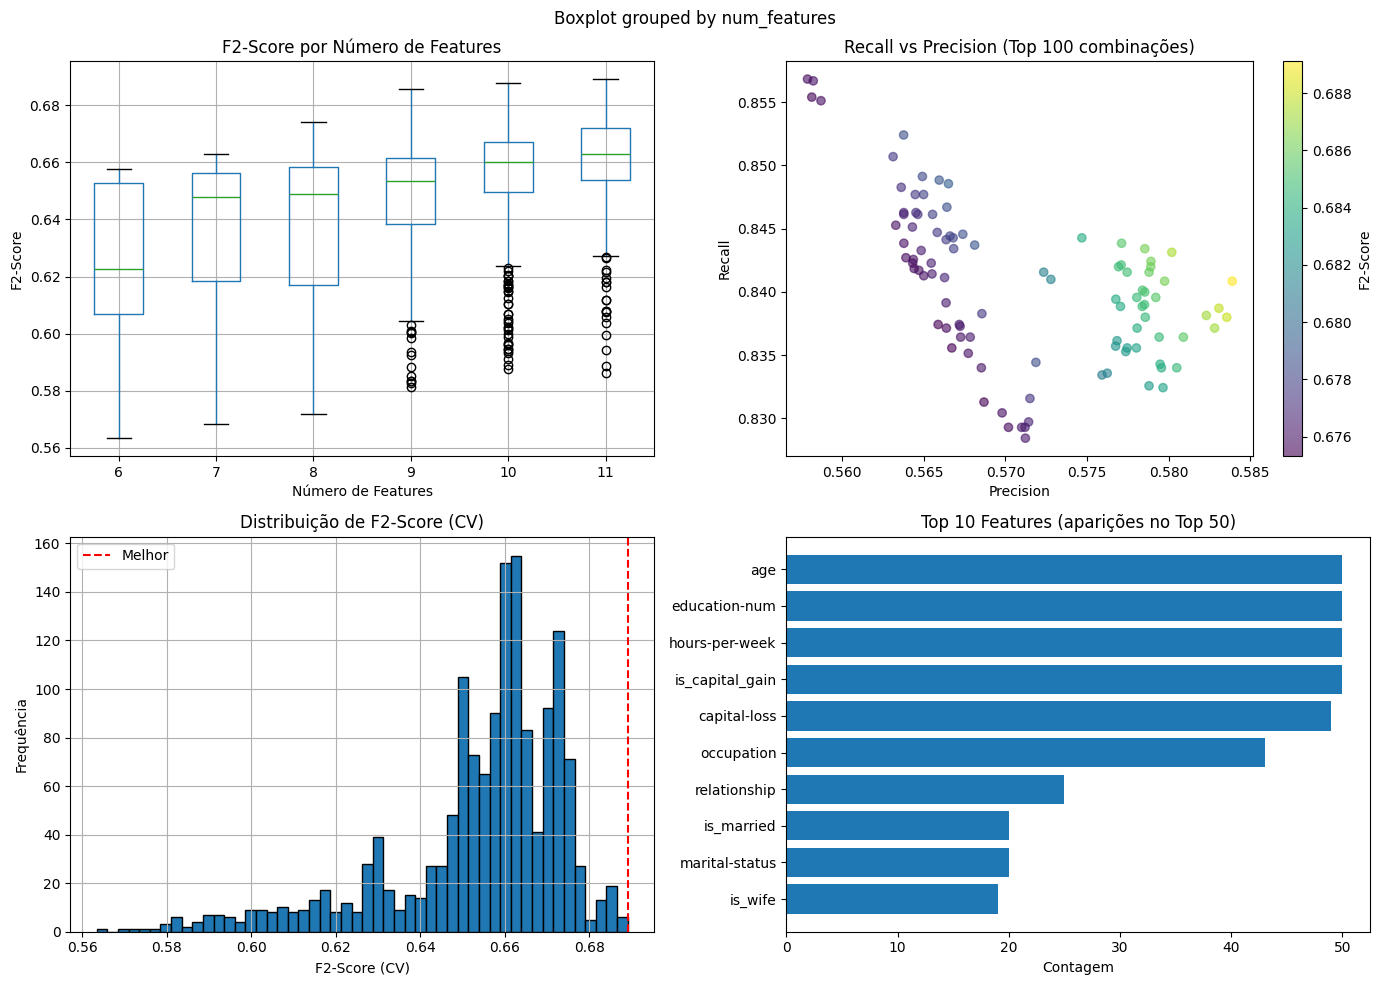


✅ Resultados salvos em: feature_combination_results.csv


In [0]:
import pandas as pd
import mlflow

# 5. Análise dos resultados

# Verificar se 'results' foi populado corretamente
if not isinstance(results, list) or len(results) == 0 or results == [...]:
    print("⚠️ A variável 'results' não está disponível na sessão.")
    print("📥 Carregando resultados dos logs do MLflow...\n")

    # Carregar resultados do MLflow
    mlflow.set_experiment("/Users/brenofontesx@gmail.com/Adult_Income/adult_income_exp")
    experiment = mlflow.get_experiment_by_name("/Users/brenofontesx@gmail.com/Adult_Income/adult_income_exp_f1")

    if experiment is None:
        print("❌ ERRO: Experimento MLflow não encontrado.")
        print("\n📋 SOLUÇÃO:")
        print("   Execute Cell Run All Experiment primeiro para gerar os experimentos.")
        print("\n⚠️ NOTA: Cell pode levar várias horas dependendo do número de experimentos.")
        raise ValueError("Experimento MLflow não encontrado")

    # Buscar todas as runs do experimento
    runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

    if len(runs) == 0:
        print("❌ ERRO: Nenhuma run encontrada no experimento MLflow.")
        print("\n📋 SOLUÇÃO:")
        print("   Execute Cell Run All Experiments primeiro para gerar os experimentos.")
        raise ValueError("Nenhuma run encontrada no MLflow")

    # Reconstruir o DataFrame de resultados a partir das runs do MLflow
    results_data = []
    for idx, run in runs.iterrows():
        try:
            results_data.append({
                'experiment_id': int(run['tags.mlflow.runName'].split('_')[1]) if 'tags.mlflow.runName' in run and run['tags.mlflow.runName'] else idx + 1,
                'num_features': int(run['params.num_features']) if 'params.num_features' in run and pd.notna(run['params.num_features']) else None,
                'features': run['params.features'] if 'params.features' in run else '',
                'recall_cv_mean': run['metrics.recall_cv_mean'] if 'metrics.recall_cv_mean' in run else None,
                'precision_cv_mean': run['metrics.precision_cv_mean'] if 'metrics.precision_cv_mean' in run else None,
                'f2_cv_mean': run['metrics.f2_cv_mean'] if 'metrics.f2_cv_mean' in run else None,
                'f2_cv_std': run['metrics.f2_cv_std'] if 'metrics.f2_cv_std' in run else None,
                'status': 'success' if pd.notna(run.get('metrics.f2_cv_mean')) else 'failed'
            })
        except Exception as e:
            # Skip runs que não têm os dados esperados
            continue

    results_df = pd.DataFrame(results_data)
    print(f"✅ Carregados {len(results_df)} experimentos do MLflow.\n")
else:
    results_df = pd.DataFrame(results)

# Verificar se o DataFrame tem as colunas esperadas
if 'status' not in results_df.columns:
    print("❌ ERRO: DataFrame 'results_df' não contém a coluna 'status'.")
    print("\nColunas disponíveis:", results_df.columns.tolist())
    raise ValueError("Coluna 'status' não encontrada em results_df")

# Filtrar apenas experimentos bem-sucedidos
successful_results = results_df[results_df['status'] == 'success'].copy()

if len(successful_results) > 0:
    # Ordenar por F2-Score (métrica que favorece recall)
    successful_results = successful_results.sort_values('f2_cv_mean', ascending=False)

    print("="*80)
    print("TOP 20 COMBINAÇÕES DE FEATURES (ordenado por F2-Score)")
    print("="*80)
    display(successful_results[['experiment_id', 'num_features', 'features', 'recall_cv_mean', 'precision_cv_mean', 'f2_cv_mean', 'f2_cv_std']].head(20))

    print("\n" + "="*80)
    print("ESTATÍSTICAS GERAIS")
    print("="*80)
    print(f"\nMétricas médias por número de features:")
    stats_by_size = successful_results.groupby('num_features')[['recall_cv_mean', 'precision_cv_mean', 'f2_cv_mean', 'f2_cv_std']].agg(['mean', 'std', 'min', 'max'])
    display(stats_by_size)

    # Melhor combinação geral
    best_combo = successful_results.iloc[0]
    print("\n" + "="*80)
    print("⭐ MELHOR COMBINAÇÃO GERAL (F2-Score)")
    print("="*80)
    print(f"Experimento ID: {best_combo['experiment_id']}")
    print(f"Número de features: {best_combo['num_features']}")
    print(f"Features: {best_combo['features']}")
    print(f"\nMétricas:")
    print(f"  Recall (CV): {best_combo['recall_cv_mean']:.4f}")
    print(f"  Precision (CV): {best_combo['precision_cv_mean']:.4f}")
    print(f"  F2-Score (CV): {best_combo['f2_cv_mean']:.4f}")
    print(f"  F2-Score Std (CV): {best_combo['f2_cv_std']:.4f}")

    # Visualização
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Gráfico 1: F2-Score por número de features
    successful_results.boxplot(column='f2_cv_mean', by='num_features', ax=axes[0, 0])
    axes[0, 0].set_title('F2-Score por Número de Features')
    axes[0, 0].set_xlabel('Número de Features')
    axes[0, 0].set_ylabel('F2-Score')

    # Gráfico 2: Recall vs Precision (top 100)
    top_100 = successful_results.head(100)
    scatter = axes[0, 1].scatter(top_100['precision_cv_mean'], top_100['recall_cv_mean'],
                                  c=top_100['f2_cv_mean'], cmap='viridis', alpha=0.6)
    axes[0, 1].set_title('Recall vs Precision (Top 100 combinações)')
    axes[0, 1].set_xlabel('Precision')
    axes[0, 1].set_ylabel('Recall')
    plt.colorbar(scatter, ax=axes[0, 1], label='F2-Score')

    # Gráfico 3: Distribuição de F2-Score (CV)
    successful_results['f2_cv_mean'].hist(bins=50, ax=axes[1, 0], edgecolor='black')
    axes[1, 0].set_title('Distribuição de F2-Score (CV)')
    axes[1, 0].set_xlabel('F2-Score (CV)')
    axes[1, 0].set_ylabel('Frequência')
    axes[1, 0].axvline(best_combo['f2_cv_mean'], color='red', linestyle='--', label='Melhor')
    axes[1, 0].legend()

    # Gráfico 4: Top 10 features (contagem de aparições no top 50)
    top_50 = successful_results.head(50)
    all_top_features = []
    for features_str in top_50['features']:
        all_top_features.extend([f.strip() for f in features_str.split(',')])

    from collections import Counter
    feature_counts = Counter(all_top_features)
    top_features_df = pd.DataFrame(feature_counts.most_common(10), columns=['Feature', 'Count'])

    axes[1, 1].barh(top_features_df['Feature'], top_features_df['Count'])
    axes[1, 1].set_title('Top 10 Features (aparições no Top 50)')
    axes[1, 1].set_xlabel('Contagem')
    axes[1, 1].invert_yaxis()

    plt.tight_layout()
    plt.show()

    # Salvar resultados em CSV
    results_csv_path = "feature_combination_results.csv"
    successful_results.to_csv(results_csv_path, index=False)
    print(f"\n✅ Resultados salvos em: {results_csv_path}")

else:
    print("⚠️ Nenhum experimento bem-sucedido encontrado.")

In [ ]:
# Comparar performance Treino vs Teste APENAS da melhor combinação

if len(successful_results) > 0:
    print("="*100)
    print("🔍 ANÁLISE: TREINO vs TESTE - Melhor Combinação")
    print("="*100)

    # Pegar a melhor combinação (maior F2-Score no teste)
    best_combo = successful_results.iloc[0]
    best_features_str = best_combo['features']
    best_features = [f.strip() for f in best_features_str.split(',')]

    print(f"\n📋 Melhor combinação (Experimento {best_combo['experiment_id']}):")
    print(f"   Features ({len(best_features)}): {best_features}")
    print(f"   F2-Score (CV): {best_combo['f2_cv_mean']:.4f}\n")

    # CatBoost: sem ColumnTransformer/OHE/scaling — cat_features nativo
    X_train_best, cat_cols_best = prepare_catboost_input(df_train, best_features)
    X_test_best, _ = prepare_catboost_input(df_test, best_features)

    pipeline_best = CatBoostClassifier(
        cat_features=cat_cols_best,
        **best_cb_params,
        random_state=42,
        auto_class_weights='Balanced',
        eval_metric='Logloss',
        verbose=False
    )

    # ====== TREINAR ======
    pipeline_best.fit(X_train_best, y_train)

    # ====== AVALIAR NO TREINO ======
    y_train_pred = pipeline_best.predict(X_train_best)
    y_train_pred_proba = pipeline_best.predict_proba(X_train_best)[:, 1]

    recall_train = recall_score(y_train, y_train_pred)
    precision_train = precision_score(y_train, y_train_pred)
    f1_train = f1_score(y_train, y_train_pred)
    f2_train = fbeta_score(y_train, y_train_pred, beta=1)
    auc_train = roc_auc_score(y_train, y_train_pred_proba)

    # ====== AVALIAR NO TESTE ======
    y_test_pred = pipeline_best.predict(X_test_best)
    y_test_pred_proba = pipeline_best.predict_proba(X_test_best)[:, 1]

    recall_test = recall_score(y_test, y_test_pred)
    precision_test = precision_score(y_test, y_test_pred)
    f1_test = f1_score(y_test, y_test_pred)
    f2_test = fbeta_score(y_test, y_test_pred, beta=1)
    auc_test = roc_auc_score(y_test, y_test_pred_proba)

    # ====== CALCULAR GAP ======
    recall_gap = recall_train - recall_test
    precision_gap = precision_train - precision_test
    f1_gap = f1_train - f1_test
    f2_gap = f2_train - f2_test
    auc_gap = auc_train - auc_test

    # Criar DataFrame de comparação
    comparison_data = {
        'Métrica': ['Recall', 'Precision', 'F1-Score', 'F2-Score', 'AUC'],
        'Treino (60%)': [recall_train, precision_train, f1_train, f2_train, auc_train],
        'Teste (20%)': [recall_test, precision_test, f1_test, f2_test, auc_test],
        'GAP (Treino - Teste)': [recall_gap, precision_gap, f1_gap, f2_gap, auc_gap],
        'GAP %': [
            (recall_gap/recall_train*100) if recall_train > 0 else 0,
            (precision_gap/precision_train*100) if precision_train > 0 else 0,
            (f1_gap/f1_train*100) if f1_train > 0 else 0,
            (f2_gap/f2_train*100) if f2_train > 0 else 0,
            (auc_gap/auc_train*100) if auc_train > 0 else 0
        ]
    }

    comparison_df = pd.DataFrame(comparison_data)

    print("\n" + "="*100)
    print("📊 COMPARAÇÃO: TREINO vs TESTE")
    print("="*100)
    display(comparison_df.style.format({
        'Treino (60%)': '{:.4f}',
        'Teste (20%)': '{:.4f}',
        'GAP (Treino - Teste)': '{:.4f}',
        'GAP %': '{:.2f}%'
    }))

    # Interpretação do GAP
    print("\n" + "="*100)
    print("🔍 INTERPRETAÇÃO")
    print("="*100)

    avg_gap = comparison_df['GAP (Treino - Teste)'].mean()

    print(f"\n📈 GAP Médio (todas métricas): {avg_gap:.4f}\n")

    if f2_gap > 0.05:
        print("⚠️ OVERFITTING DETECTADO (F2 Gap > 0.05)")
        print("   O modelo performa significativamente melhor no treino que no teste.")
        print("   Sugestões:")
        print("   • Usar regularização mais forte (aumentar l2_leaf_reg / reduzir depth)")
        print("   • Reduzir número de features")
        print("   • Usar cross-validation")
    elif f2_gap < -0.02:
        print("⚠️ INCONSISTÊNCIA (F2 Gap < -0.02)")
        print("   O modelo performa melhor no teste que no treino (raro).")
        print("   Verificar possíveis problemas nos dados.")
    else:
        print("✅ BOA GENERALIZAÇÃO (F2 Gap ≈ 0)")
        print("   O modelo não está sofrendo overfitting significativo.")
        print("   A performance no treino e teste é similar.")

    # Visualização
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico 1: Comparação Treino vs Teste
    metrics = comparison_df['Métrica']
    train_values = comparison_df['Treino (60%)']
    test_values = comparison_df['Teste (20%)']

    x = range(len(metrics))
    width = 0.35

    axes[0].bar([i - width/2 for i in x], train_values, width, label='Treino (60%)', alpha=0.8, color='skyblue')
    axes[0].bar([i + width/2 for i in x], test_values, width, label='Teste (20%)', alpha=0.8, color='orange')
    axes[0].set_xlabel('Métrica')
    axes[0].set_ylabel('Valor')
    axes[0].set_title('Comparação: Treino vs Teste')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metrics, rotation=45, ha='right')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3, axis='y')

    # Gráfico 2: GAP por Métrica
    gap_values = comparison_df['GAP (Treino - Teste)']
    colors = ['red' if gap > 0.05 else 'green' if abs(gap) < 0.02 else 'orange' for gap in gap_values]

    axes[1].barh(metrics, gap_values, color=colors, alpha=0.7)
    axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
    axes[1].axvline(0.05, color='red', linestyle=':', linewidth=1, alpha=0.5, label='Limite Overfitting')
    axes[1].axvline(-0.02, color='red', linestyle=':', linewidth=1, alpha=0.5)
    axes[1].set_xlabel('GAP (Treino - Teste)')
    axes[1].set_title('GAP por Métrica')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='x')

    plt.tight_layout()
    plt.show()

    print("\n" + "="*100)
    print("✅ ANÁLISE CONCLUÍDA")
    print("="*100)

else:
    print("⚠️ Execute primeiro a célula 21 (experimentos) para ter resultados disponíveis.")


## Train vs Test vs Validation Analysis

In [ ]:
# Comparar performance do melhor modelo em TODOS os 3 conjuntos

if len(successful_results) > 0:
    print("="*100)
    print("📊 ANÁLISE COMPLETA: TREINO (60%) vs VALIDAÇÃO (20%) vs TESTE (20%)")
    print("="*100)

    # Pegar a melhor combinação
    best_combo = successful_results.iloc[0]
    best_features_str = best_combo['features']
    best_features = [f.strip() for f in best_features_str.split(',')]

    print(f"\n📋 Melhor combinação (Experimento {best_combo['experiment_id']}):")
    print(f"   Features ({len(best_features)}): {best_features}\n")

    # CatBoost: sem ColumnTransformer/OHE/scaling — cat_features nativo
    X_train_best, cat_cols_best = prepare_catboost_input(df_train, best_features)
    X_val_best, _ = prepare_catboost_input(df_val, best_features)
    X_test_best, _ = prepare_catboost_input(df_test, best_features)

    pipeline_best = CatBoostClassifier(
        cat_features=cat_cols_best,
        **best_cb_params,
        random_state=42,
        auto_class_weights='Balanced',
        eval_metric='Logloss',
        verbose=False
    )

    # ====== TREINAR ======
    pipeline_best.fit(X_train_best, y_train)

    # ====== AVALIAR NO TREINO (60%) ======
    y_train_pred = pipeline_best.predict(X_train_best)
    y_train_pred_proba = pipeline_best.predict_proba(X_train_best)[:, 1]

    recall_train = recall_score(y_train, y_train_pred)
    precision_train = precision_score(y_train, y_train_pred)
    f1_train = f1_score(y_train, y_train_pred)
    f2_train = fbeta_score(y_train, y_train_pred, beta=1)
    auc_train = roc_auc_score(y_train, y_train_pred_proba)

    # ====== AVALIAR NA VALIDAÇÃO (20%) ======
    y_val_pred = pipeline_best.predict(X_val_best)
    y_val_pred_proba = pipeline_best.predict_proba(X_val_best)[:, 1]

    recall_val = recall_score(y_val, y_val_pred)
    precision_val = precision_score(y_val, y_val_pred)
    f1_val = f1_score(y_val, y_val_pred)
    f2_val = fbeta_score(y_val, y_val_pred, beta=1)
    auc_val = roc_auc_score(y_val, y_val_pred_proba)

    # ====== AVALIAR NO TESTE (20%) ======
    y_test_pred = pipeline_best.predict(X_test_best)
    y_test_pred_proba = pipeline_best.predict_proba(X_test_best)[:, 1]

    recall_test = recall_score(y_test, y_test_pred)
    precision_test = precision_score(y_test, y_test_pred)
    f1_test = f1_score(y_test, y_test_pred)
    f2_test = fbeta_score(y_test, y_test_pred, beta=1)
    auc_test = roc_auc_score(y_test, y_test_pred_proba)

    # ====== CRIAR DATAFRAME DE COMPARAÇÃO ======
    comparison_3sets = pd.DataFrame({
        'Métrica': ['Recall', 'Precision', 'F1-Score', 'F2-Score', 'AUC'],
        'Treino (60%)': [recall_train, precision_train, f1_train, f2_train, auc_train],
        'Validação (20%)': [recall_val, precision_val, f1_val, f2_val, auc_val],
        'Teste (20%)': [recall_test, precision_test, f1_test, f2_test, auc_test]
    })

    # Calcular desvio padrão entre os 3 conjuntos (estabilidade)
    comparison_3sets['Desvio Padrão'] = comparison_3sets[['Treino (60%)', 'Validação (20%)', 'Teste (20%)']].std(axis=1)
    _cols3 = ['Treino (60%)', 'Validação (20%)', 'Teste (20%)']
    comparison_3sets['Range'] = comparison_3sets[_cols3].max(axis=1) - comparison_3sets[_cols3].min(axis=1)

    print("\n" + "="*100)
    print("📊 COMPARAÇÃO: TREINO vs VALIDAÇÃO vs TESTE")
    print("="*100)
    display(comparison_3sets.style.format({
        'Treino (60%)': '{:.4f}',
        'Validação (20%)': '{:.4f}',
        'Teste (20%)': '{:.4f}',
        'Desvio Padrão': '{:.4f}',
        'Range': '{:.4f}'
    }).background_gradient(subset=['Desvio Padrão', 'Range'], cmap='RdYlGn_r'))

    # Interpretação
    print("\n" + "="*100)
    print("🔍 INTERPRETAÇÃO")
    print("="*100)

    avg_std = comparison_3sets['Desvio Padrão'].mean()
    avg_range = comparison_3sets['Range'].mean()

    print(f"\n📈 Desvio Padrão Médio: {avg_std:.4f}")
    print(f"📈 Range Médio: {avg_range:.4f}\n")

    if avg_std < 0.02:
        print("✅ EXCELENTE CONSISTÊNCIA")
        print("   O modelo performa de forma muito similar nos 3 conjuntos.")
        print("   Alta confiabilidade e boa generalização!")
    elif avg_std < 0.04:
        print("✅ BOA CONSISTÊNCIA")
        print("   O modelo performa de forma consistente nos 3 conjuntos.")
        print("   Generalização adequada.")
    else:
        print("⚠️ VARIABILIDADE DETECTADA")
        print("   Há diferenças significativas entre os conjuntos.")
        print("   Revisar possível overfitting ou underfitting.")

    # Análise específica por conjunto
    print("\n🎯 Análise Detalhada (F2-Score):")
    f2_values = [f2_train, f2_val, f2_test]
    f2_labels = ['Treino', 'Validação', 'Teste']
    best_set_idx = f2_values.index(max(f2_values))
    worst_set_idx = f2_values.index(min(f2_values))

    print(f"   • Melhor: {f2_labels[best_set_idx]} ({f2_values[best_set_idx]:.4f})")
    print(f"   • Pior: {f2_labels[worst_set_idx]} ({f2_values[worst_set_idx]:.4f})")
    print(f"   • Diferença: {max(f2_values) - min(f2_values):.4f}")

    if best_set_idx == 0:
        print("\n   ⚠️ Treino tem melhor performance → Possível leve overfitting")
    elif f2_val > f2_train and f2_test > f2_train:
        print("\n   ⚠️ Validação e Teste superam Treino → Verificar dados ou randomização")
    else:
        print("\n   ✅ Performance equilibrada entre os conjuntos")

    # Visualização
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Gráfico 1: Comparação por Métrica
    metrics = comparison_3sets['Métrica']
    x = range(len(metrics))
    width = 0.25

    axes[0].bar([i - width for i in x], comparison_3sets['Treino (60%)'], width,
                label='Train (60%)', alpha=0.8, color='skyblue')
    axes[0].bar([i for i in x], comparison_3sets['Validação (20%)'], width,
                label='Validation (20%)', alpha=0.8, color='lightgreen')
    axes[0].bar([i + width for i in x], comparison_3sets['Teste (20%)'], width,
                label='Test (20%)', alpha=0.8, color='orange')
    axes[0].set_xlabel('Metric')
    axes[0].set_ylabel('Value')
    axes[0].set_title('Comparison: Train vs Validation vs Test')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metrics, rotation=45, ha='right')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3, axis='y')

    # Gráfico 2: Desvio Padrão (Estabilidade)
    colors_std = ['green' if std < 0.02 else 'orange' if std < 0.04 else 'red'
                  for std in comparison_3sets['Desvio Padrão']]
    axes[1].barh(metrics, comparison_3sets['Desvio Padrão'], color=colors_std, alpha=0.7)
    axes[1].axvline(0.02, color='green', linestyle='--', linewidth=1, alpha=0.5, label='Limite Bom')
    axes[1].axvline(0.04, color='orange', linestyle='--', linewidth=1, alpha=0.5, label='Limite Aceitável')
    axes[1].set_xlabel('Desvio Padrão')
    axes[1].set_title('Estabilidade entre Conjuntos')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='x')

    # Gráfico 3: Linha - Evolução por Conjunto
    for i, metric in enumerate(metrics):
        values = [comparison_3sets.iloc[i]['Treino (60%)'],
                 comparison_3sets.iloc[i]['Validação (20%)'],
                 comparison_3sets.iloc[i]['Teste (20%)']]
        axes[2].plot(['Treino\n(60%)', 'Validação\n(20%)', 'Teste\n(20%)'], values,
                     marker='o', label=metric, linewidth=2, markersize=8)

    axes[2].set_ylabel('Valor')
    axes[2].set_title('Performance por Conjunto')
    axes[2].legend(loc='best')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n" + "="*100)
    print("✅ ANÁLISE COMPLETA CONCLUÍDA")
    print("="*100)
    print("\n💡 Resumo:")
    print(f"   • Os 3 conjuntos têm {len(df_train):,}, {len(df_val):,} e {len(df_test):,} registros")
    print(f"   • A melhor combinação usa {len(best_features)} features")
    print(f"   • Desvio padrão médio entre conjuntos: {avg_std:.4f}")
    print(f"   • F2-Score médio: {(f2_train + f2_val + f2_test)/3:.4f}")

else:
    print("⚠️ Execute primeiro a célula 21 (experimentos) para ter resultados disponíveis.")


## Confusion Matrix & Precision-Recall Analysis

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Garantir que estamos pegando o MELHOR de TODOS os experimentos
successful_results = results_df[results_df['status'] == 'success'].sort_values('f2_cv_mean', ascending=False)

# Check if there are any successful experiments
if len(successful_results) == 0:
    print("❌ ERRO: Nenhum experimento foi executado com sucesso.")
    print(f"\nTotal de experimentos: {len(results_df)}")
    print(f"Experimentos bem-sucedidos: 0")
    print("\n📋 SOLUÇÃO:")
    print("   1. Verifique Cell 11 (Run All Experiments) para ver os erros dos experimentos")
    print("   2. Corrija os erros e execute Cell 11 novamente")
    print("   3. Depois execute esta célula novamente")
    raise ValueError("Nenhum experimento bem-sucedido encontrado")

best_combo = successful_results.iloc[0]
best_features = [f.strip() for f in best_combo['features'].split(',')]

print(f"🏆 Melhor experimento: {best_combo['experiment_id']}")
print(f"   Features ({len(best_features)}): {best_features}")
print(f"   F2-Score: {best_combo['f2_cv_mean']:.4f}")
print(f"   Precision: {best_combo['precision_cv_mean']:.4f}")
print(f"   Recall: {best_combo['recall_cv_mean']:.4f}\n")

# 2. CatBoost: sem ColumnTransformer/OHE/scaling — cat_features nativo
X_train_best, cat_cols_best = prepare_catboost_input(df_train, best_features)
X_test_best, _ = prepare_catboost_input(df_test, best_features)

pipeline_best = CatBoostClassifier(
    cat_features=cat_cols_best,
    **best_cb_params,
    random_state=42,
    auto_class_weights='Balanced',
    eval_metric='Logloss',
    verbose=False
)

# 3. Treinar e avaliar no teste
pipeline_best.fit(X_train_best, y_train)

y_test_pred = pipeline_best.predict(X_test_best)
y_test_pred_proba_best = pipeline_best.predict_proba(X_test_best)[:, 1]

# 4. Matriz de confusão
cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(cmap='Blues')
plt.title(f'Matriz de Confusão — Melhor Experimento (F2={best_combo["f2_cv_mean"]:.4f})')
plt.show()


In [ ]:
# Threshold Tuning — otimizar decisão para F2-Score no conjunto de VALIDAÇÃO
import numpy as np
from sklearn.metrics import fbeta_score, precision_score, recall_score
import matplotlib.pyplot as plt

print("="*100)
print("🎯 THRESHOLD TUNING - Otimização de F2-Score")
print("="*100)

# 1. Preparar X_val com as mesmas features do melhor experimento
X_val_best, _ = prepare_catboost_input(df_val, best_features)  # CatBoost exige mesma tipagem categórica do fit

# 2. Obter probabilidades no conjunto de VALIDAÇÃO (nunca visto pelo threshold search)
y_proba_val = pipeline_best.predict_proba(X_val_best)[:, 1]

# 3. Varrer thresholds e calcular F2 para cada um
thresholds = np.arange(0.05, 0.95, 0.01)
f2_scores = [fbeta_score(y_val, (y_proba_val >= t).astype(int), beta=1) for t in thresholds]

best_idx = np.argmax(f2_scores)
best_threshold = thresholds[best_idx]
best_f2_val = f2_scores[best_idx]

print(f"\n📊 Threshold default (0.50): F2 = {fbeta_score(y_val, (y_proba_val >= 0.5).astype(int), beta=1):.4f}")
print(f"📊 Threshold ótimo ({best_threshold:.2f}): F2 = {best_f2_val:.4f}")
print(f"📈 Ganho: {best_f2_val - fbeta_score(y_val, (y_proba_val >= 0.5).astype(int), beta=1):+.4f}")

# 4. Visualização da curva F2 vs threshold
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f2_scores, color='darkorange', lw=2)
plt.axvline(best_threshold, color='green', linestyle='--', label=f'Ótimo = {best_threshold:.2f}')
plt.axvline(0.5, color='gray', linestyle=':', label='Default = 0.50')
plt.xlabel('Threshold')
plt.ylabel('F2-Score (validação)')
plt.title('F2-Score vs Threshold de Decisão')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. VALIDAÇÃO FINAL — aplicar o threshold escolhido no conjunto de TESTE (só agora)
X_test_best, _ = prepare_catboost_input(df_test, best_features)  # já deve existir, recriado por segurança
y_proba_test = pipeline_best.predict_proba(X_test_best)[:, 1]
y_pred_test_tuned = (y_proba_test >= best_threshold).astype(int)

f2_test_tuned = fbeta_score(y_test, y_pred_test_tuned, beta=1)
f2_test_default = fbeta_score(y_test, (y_proba_test >= 0.5).astype(int), beta=1)

print(f"\n{'='*100}")
print("✅ RESULTADO NO CONJUNTO DE TESTE (avaliação final, imparcial)")
print(f"{'='*100}")
print(f"F2 (threshold 0.50):        {f2_test_default:.4f}")
print(f"F2 (threshold {best_threshold:.2f}):        {f2_test_tuned:.4f}")
print(f"Recall (threshold {best_threshold:.2f}):     {recall_score(y_test, y_pred_test_tuned):.4f}")
print(f"Precision (threshold {best_threshold:.2f}):  {precision_score(y_test, y_pred_test_tuned):.4f}")

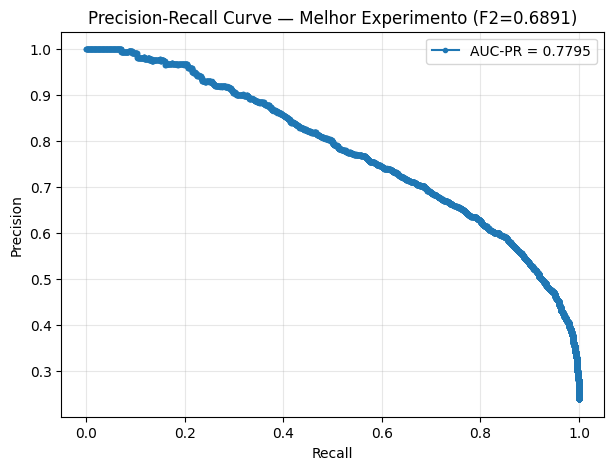

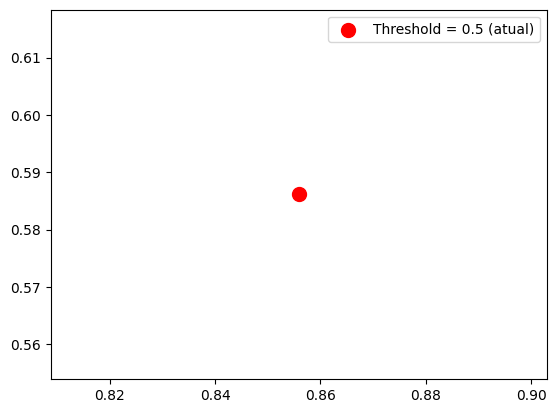

In [0]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_test, y_test_pred_proba_best)
auc_pr = average_precision_score(y_test, y_test_pred_proba_best)

plt.figure(figsize=(7,5))
plt.plot(recall, precision, marker='.', label=f'AUC-PR = {auc_pr:.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve — Melhor Experimento (F2={best_combo["f2_cv_mean"]:.4f})')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Marcar o ponto do threshold atual (0.5) na curva
idx_threshold_05 = (thresholds >= 0.5).argmax()
plt.scatter(recall[idx_threshold_05], precision[idx_threshold_05],
            color='red', s=100, zorder=5, label='Threshold = 0.5 (atual)')
plt.legend()

In [0]:
from sklearn.metrics import roc_auc_score, average_precision_score

auc_roc = roc_auc_score(y_test, y_test_pred_proba)
auc_pr = average_precision_score(y_test, y_test_pred_proba)

print("AUC-ROC:", auc_roc)
print("AUC-PR:", auc_pr)

AUC-ROC: 0.9116381689588123
AUC-PR: 0.7795266852278242


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import fbeta_score, confusion_matrix, ConfusionMatrixDisplay

# LogReg exige OHE+scaling; CatBoost usa cat_features nativo (sem OHE/scaling).
# O VotingClassifier do sklearn aplica o MESMO X a todos os estimadores -> incompatível aqui.
# Combinação feita manualmente por média ponderada de probabilidades (weights=[1,2], igual ao original).

numeric_in_combo = [f for f in best_features if f in all_numeric_features]
categorical_in_combo = [f for f in best_features if f in all_categorical_features]
binary_in_combo = [f for f in best_features if f in all_binary_features]

logreg_preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_in_combo),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), categorical_in_combo),
    ('bin', Pipeline([('imputer', SimpleImputer(strategy='most_frequent'))]), binary_in_combo),
])

logreg_clf = Pipeline([
    ('preprocessor', logreg_preprocessor),
    ('classifier', LogisticRegression(max_iter=250, class_weight='balanced', random_state=42))
])
logreg_clf.fit(df_train[best_features], y_train)

proba_logreg_test = logreg_clf.predict_proba(df_test[best_features])[:, 1]
proba_cb_test = pipeline_best.predict_proba(X_test_best)[:, 1]

w_logreg, w_cb = 1, 2  # pesos equivalentes ao VotingClassifier original ([1, 2])
y_proba_voting = (w_logreg * proba_logreg_test + w_cb * proba_cb_test) / (w_logreg + w_cb)
y_pred_voting = (y_proba_voting >= 0.5).astype(int)

f2_voting = fbeta_score(y_test, y_pred_voting, beta=1)
print(f"F2-Score (Voting): {f2_voting:.4f}")

cm = confusion_matrix(y_test, y_pred_voting)
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(cmap='Blues')


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import fbeta_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# O StackingClassifier do sklearn também aplica o MESMO X a todos os estimadores base ->
# mesma incompatibilidade da célula de Voting (LogReg precisa de OHE+scaling, CatBoost não).
# Stacking implementado manualmente com probabilidades out-of-fold (OOF) no treino,
# para o meta-modelo não vazar dados de treino para si mesmo.

cv_stack = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_train_idx = y_train.reset_index(drop=True)
X_train_best_idx = X_train_best.reset_index(drop=True)
df_train_logreg_idx = df_train[best_features].reset_index(drop=True)

oof_proba_logreg = np.zeros(len(y_train_idx))
oof_proba_cb = np.zeros(len(y_train_idx))

for fold_train_idx, fold_val_idx in cv_stack.split(X_train_best_idx, y_train_idx):
    # LogReg (OHE+scaling refeito por fold)
    fold_logreg = Pipeline([
        ('preprocessor', logreg_preprocessor),
        ('classifier', LogisticRegression(max_iter=250, class_weight='balanced', random_state=42))
    ])
    fold_logreg.fit(df_train_logreg_idx.iloc[fold_train_idx], y_train_idx.iloc[fold_train_idx])
    oof_proba_logreg[fold_val_idx] = fold_logreg.predict_proba(df_train_logreg_idx.iloc[fold_val_idx])[:, 1]

    # CatBoost (cat_features nativo)
    fold_cb = CatBoostClassifier(
        cat_features=cat_cols_best,
        **best_cb_params,
        random_state=42,
        auto_class_weights='Balanced',
        eval_metric='Logloss',
        verbose=False
    )
    fold_cb.fit(X_train_best_idx.iloc[fold_train_idx], y_train_idx.iloc[fold_train_idx])
    oof_proba_cb[fold_val_idx] = fold_cb.predict_proba(X_train_best_idx.iloc[fold_val_idx])[:, 1]

meta_model = LogisticRegression(max_iter=250, class_weight='balanced', random_state=42)
meta_model.fit(np.column_stack([oof_proba_logreg, oof_proba_cb]), y_train_idx)

# Base learners no teste: reutiliza logreg_clf e pipeline_best já treinados no treino completo (célula 20/16)
test_proba_logreg = logreg_clf.predict_proba(df_test[best_features])[:, 1]
test_proba_cb = pipeline_best.predict_proba(X_test_best)[:, 1]

y_proba_stacking = meta_model.predict_proba(np.column_stack([test_proba_logreg, test_proba_cb]))[:, 1]
y_pred_stacking = meta_model.predict(np.column_stack([test_proba_logreg, test_proba_cb]))

# Previsões já calculadas: y_pred_voting (Cell 20), pipeline_best (Cell 16)
y_pred_cb = pipeline_best.predict(X_test_best)

f2_cb = fbeta_score(y_test, y_pred_cb, beta=1)
f2_voting = fbeta_score(y_test, y_pred_voting, beta=1)
f2_stacking = fbeta_score(y_test, y_pred_stacking, beta=1)

print(f"\n📈 F2-Score CatBoost:  {f2_cb:.4f}")
print(f"📈 F2-Score Voting:    {f2_voting:.4f}")
print(f"📈 F2-Score Stacking:  {f2_stacking:.4f}")

scores = {'CatBoost': f2_cb, 'Voting': f2_voting, 'Stacking': f2_stacking}
best_model_name = max(scores, key=scores.get)
print(f"\n✅ MELHOR MODELO: {best_model_name} (F2={scores[best_model_name]:.4f})")
if best_model_name != 'CatBoost' and scores[best_model_name] - f2_cb <= 0.005:
    print("   Ganho marginal — considerar manter CatBoost por simplicidade.")

cm = confusion_matrix(y_test, y_pred_stacking)
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(cmap='Blues')


## Feature Importance Analysis

In [ ]:
# Feature Importance for Best Model (CatBoost)
import numpy as np
import matplotlib.pyplot as plt

if len(successful_results) > 0:
    print("="*100)
    print("🎯 FEATURE IMPORTANCE - Melhor Modelo (CatBoost)")
    print("="*100)

    # Pegar a melhor combinação
    best_combo = successful_results.iloc[0]
    best_features_str = best_combo['features']
    best_features = [f.strip() for f in best_features_str.split(',')]

    print(f"\n📋 Melhor combinação (Experimento {best_combo['experiment_id']}):")
    print(f"   Features ({len(best_features)}): {best_features}")
    print(f"   F2-Score (CV): {best_combo['f2_cv_mean']:.4f}\n")

    # CatBoost: sem ColumnTransformer/OHE/scaling — cat_features nativo
    X_train_best, cat_cols_best = prepare_catboost_input(df_train, best_features)

    print("="*100)
    print("🚀 CATBOOST - Feature Importance")
    print("="*100)

    pipeline_cb = CatBoostClassifier(
        cat_features=cat_cols_best,
        **best_cb_params,
        random_state=42,
        auto_class_weights='Balanced',
        eval_metric='Logloss',
        verbose=False
    )
    pipeline_cb.fit(X_train_best, y_train)

    # feature_importances_ já referencia diretamente os nomes de coluna originais
    # (sem expansão OHE, logo sem necessidade de reagregar dummies por coluna original)
    cb_importances = pipeline_cb.feature_importances_
    feature_names = X_train_best.columns.tolist()

    cb_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': cb_importances
    })
    cb_importance_df['Importance_Pct'] = (cb_importance_df['Importance'] / cb_importance_df['Importance'].sum()) * 100
    cb_importance_df = cb_importance_df.sort_values('Importance', ascending=False)

    print("\n✅ Feature Importance (ordenadas por importância):")
    display(cb_importance_df.style.format({
        'Importance': '{:.4f}',
        'Importance_Pct': '{:.2f}%'
    }).background_gradient(subset=['Importance'], cmap='YlOrRd'))

    # ====== VISUALIZAÇÃO ======
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Gráfico 1: Top 10 Features - Bar Chart Horizontal
    cb_plot_data = cb_importance_df.head(10).sort_values('Importance')
    axes[0].barh(cb_plot_data['Feature'], cb_plot_data['Importance'], color='darkorange', alpha=0.8)
    axes[0].set_xlabel('Importance Score', fontsize=12)
    axes[0].set_title('Top 10 Features - CatBoost Importance', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3, axis='x')

    # Gráfico 2: Todas Features - Bar Chart Vertical
    cb_sorted = cb_importance_df.sort_values('Importance', ascending=False)
    axes[1].bar(range(len(cb_sorted)), cb_sorted['Importance'], color='darkorange', alpha=0.7)
    axes[1].set_xlabel('Features (ordenadas por importância)', fontsize=12)
    axes[1].set_ylabel('Importance Score', fontsize=12)
    axes[1].set_title(f'Feature Importance - Todas {len(cb_sorted)} Features', fontsize=14, fontweight='bold')
    axes[1].set_xticks(range(len(cb_sorted)))
    axes[1].set_xticklabels(cb_sorted['Feature'], rotation=90, ha='right')
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.show()

    print("\n" + "="*100)
    print("✅ ANÁLISE CONCLUÍDA")
    print("="*100)
    print(f"\n💡 Resumo:")
    print(f"   • Feature mais importante: {cb_importance_df.iloc[0]['Feature']} ({cb_importance_df.iloc[0]['Importance']:.4f} - {cb_importance_df.iloc[0]['Importance_Pct']:.2f}%)")
    print(f"   • Top 3 features representam {cb_importance_df.head(3)['Importance_Pct'].sum():.2f}% da importância total")
    print(f"   • Top 5 features representam {cb_importance_df.head(5)['Importance_Pct'].sum():.2f}% da importância total")

else:
    print("⚠️ Execute primeiro a célula 11 (experimentos) para ter resultados disponíveis.")


## ROC CURVE

In [ ]:
# ROC Curve: CatBoost vs Voting vs Stacking
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

if len(successful_results) > 0:
    print("="*100)
    print("📊 ROC CURVE - CatBoost vs Voting vs Stacking")
    print("="*100)

    best_combo = successful_results.iloc[0]
    best_features_str = best_combo['features']
    best_features = [f.strip() for f in best_features_str.split(',')]

    print(f"\n📋 Melhor combinação (Experimento {best_combo['experiment_id']}):")
    print(f"   Features ({len(best_features)}): {best_features}\n")

    # Reutiliza pipeline_best (célula 16) e as probabilidades de Voting/Stacking já calculadas
    # nas células 20 e 21 (y_proba_voting, y_proba_stacking)
    y_pred_proba_cb = pipeline_best.predict_proba(X_test_best)[:, 1]

    fpr_cb, tpr_cb, thresholds_cb = roc_curve(y_test, y_pred_proba_cb)
    auc_cb = auc(fpr_cb, tpr_cb)

    fpr_vot, tpr_vot, _ = roc_curve(y_test, y_proba_voting)
    auc_vot = auc(fpr_vot, tpr_vot)

    fpr_stk, tpr_stk, _ = roc_curve(y_test, y_proba_stacking)
    auc_stk = auc(fpr_stk, tpr_stk)

    # ====== VISUALIZAÇÃO ======
    print("\n" + "="*100)
    print("📈 ROC CURVE - CatBoost vs Voting vs Stacking")
    print("="*100)

    plt.figure(figsize=(10, 8))

    plt.plot(fpr_cb, tpr_cb, color='darkorange', lw=3,
             label=f'CatBoost (AUC = {auc_cb:.4f})')
    plt.plot(fpr_vot, tpr_vot, color='steelblue', lw=3,
             label=f'Voting (AUC = {auc_vot:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--',
             label='Random Classifier (AUC = 0.5000)')
    plt.plot(fpr_stk, tpr_stk, color='seagreen', lw=3,
         label=f'Stacking (AUC = {auc_stk:.4f})')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
    plt.ylabel('True Positive Rate (Sensitivity/Recall)', fontsize=12)
    plt.title('ROC Curve - CatBoost vs Voting vs Stacking', fontsize=14, fontweight='bold')    
    plt.legend(loc='lower right', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ====== MÉTRICAS DETALHADAS ======
    print("\n" + "="*100)
    print("📊 MÉTRICAS: CATBOOST vs VOTING vs STACKING")
    print("="*100)

    from sklearn.metrics import recall_score, precision_score, f1_score, fbeta_score

    y_pred_cb = pipeline_best.predict(X_test_best)
    # y_pred_voting e y_pred_stacking já calculados nas células 20 e 21

    metrics_data = {
        'Métrica': ['AUC', 'Recall', 'Precision', 'F1-Score', 'F2-Score'],
        'CatBoost': [auc_cb, recall_score(y_test, y_pred_cb), precision_score(y_test, y_pred_cb),
                    f1_score(y_test, y_pred_cb), fbeta_score(y_test, y_pred_cb, beta=1)],
        'Voting': [auc_vot, recall_score(y_test, y_pred_voting), precision_score(y_test, y_pred_voting),
                   f1_score(y_test, y_pred_voting), fbeta_score(y_test, y_pred_voting, beta=1)],
        'Stacking': [auc_stk, recall_score(y_test, y_pred_stacking), precision_score(y_test, y_pred_stacking),
             f1_score(y_test, y_pred_stacking), fbeta_score(y_test, y_pred_stacking, beta=1)]
    }

    metrics_df = pd.DataFrame(metrics_data)
    display(metrics_df.style.format({'CatBoost': '{:.4f}', 'Voting': '{:.4f}', 'Stacking': '{:.4f}'})
            .background_gradient(subset=['CatBoost', 'Voting','Stacking'], cmap='YlOrRd'))

    # ====== INTERPRETAÇÃO ======
    print("\n" + "="*100)
    print("🔍 INTERPRETAÇÃO")
    print("="*100)

    f2_cb = fbeta_score(y_test, y_pred_cb, beta=1)
    f2_voting = fbeta_score(y_test, y_pred_voting, beta=1)
    f2_stacking = fbeta_score(y_test, y_pred_stacking, beta=1)
    diff = f2_voting - f2_cb

    print(f"\n📈 F2-Score CatBoost: {f2_cb:.4f}")
    print(f"📈 F2-Score Voting:  {f2_voting:.4f}")
    print(f"📈 F2-Score Stacking: {f2_stacking:.4f}")

    scores = {'CatBoost': f2_cb, 'Voting': f2_voting, 'Stacking': f2_stacking}
    best_model_name = max(scores, key=scores.get)
    print(f"\n✅ MELHOR MODELO: {best_model_name} (F2={scores[best_model_name]:.4f})")
    if best_model_name != 'CatBoost' and diff <= 0.005:
        print("   Ganho marginal — considerar manter CatBoost por simplicidade.")
    elif diff > 0.005:
        print(f"\n✅ VOTING SUPERIOR (+{diff:.4f} em F2)")
        print("   Recomenda-se seguir com o modelo combinado.")
    elif diff < -0.005:
        print(f"\n✅ CATBOOST SUPERIOR ({diff:.4f} em F2)")
        print("   Ensemble não trouxe ganho — manter CatBoost isolado.")
    else:
        print(f"\n➖ SEM DIFERENÇA RELEVANTE (Δ={diff:.4f})")
        print("   Manter CatBoost isolado por simplicidade (menos custo computacional).")

    print("\n" + "="*100)
    print("✅ ANÁLISE ROC CONCLUÍDA")
    print("="*100)

else:
    print("⚠️ Execute primeiro a célula 11 (experimentos) para ter resultados disponíveis.")
